In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pandas import Grouper
from pandas.plotting import lag_plot
from pandas.plotting import autocorrelation_plot
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.graphics.gofplots import qqplot
from statsmodels.tsa.ar_model import AR

from tqdm import tqdm_notebook
from itertools import product
from typing import Union

from statsmodels.tsa.arima.model import ARIMA

import warnings
warnings.filterwarnings('ignore')


from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.statespace.varmax import VARMAX

import seaborn as sns
import statsmodels.api as sm

from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics import r2_score

import warnings
warnings.filterwarnings('ignore')

In [ ]:
'''from google.colab import files
uploaded = files.upload()
import pandas as pd'''

df = pd.read_excel("data.xlsx")
df.head()

,Fecha,Tasa Representativa del Mercado (TRM)(Promedio mensual),Tasa de política monetaria(Dato mes),Índice de Precios al Consumidor(Dato fin de mes)
0,dd/mm/aaaa,COP/USD,%,índice
1,31/01/2000,"1.923,57","12,00","40,30"
2,29/02/2000,"1.950,64","12,00","41,23"
3,31/03/2000,"1.956,25","12,00","41,93"
4,30/04/2000,"1.986,77","12,00","42,35"


In [ ]:
# Renombrar columnas
df = df.rename(columns={
    'Fecha': 'Fecha',
    'Tasa Representativa del Mercado (TRM)(Promedio mensual)': 'TRM',
    'Tasa de política monetaria(Dato mes)': 'Tasa_interes',
    'Índice de Precios al Consumidor(Dato fin de mes)': 'IPC'
})

# Eliminar primera fila si es necesario
df = df.iloc[1:].reset_index(drop=True)

# Limpieza de columnas numéricas
cols_num = ["TRM", "Tasa_interes", "IPC"]
for col in cols_num:
    if df[col].dtype == 'object':
        df[col] = df[col].astype(str).str.replace(".", "", regex=False)
        df[col] = df[col].str.replace(",", ".", regex=False)
        df[col] = df[col].astype(float)

# Convertir Fecha y establecer índice
df["Fecha"] = pd.to_datetime(df["Fecha"], format="%d/%m/%Y")
df = df.set_index("Fecha")
df = df.sort_index()

print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 310 entries, 2000-01-31 to 2025-10-31
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TRM           310 non-null    float64
 1   Tasa_interes  310 non-null    float64
 2   IPC           310 non-null    float64
dtypes: float64(3)
memory usage: 9.7 KB
None


,TRM,Tasa_interes,IPC
Fecha,,,
2000-01-31,1923.57,12.0,40.30
2000-02-29,1950.64,12.0,41.23
2000-03-31,1956.25,12.0,41.93
2000-04-30,1986.77,12.0,42.35
2000-05-31,2055.69,12.0,42.57


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 310 entries, 2000-01-31 to 2025-10-31
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TRM           310 non-null    float64
 1   Tasa_interes  310 non-null    float64
 2   IPC           310 non-null    float64
dtypes: float64(3)
memory usage: 9.7 KB


In [ ]:
df.columns

Index(['TRM', 'Tasa_interes', 'IPC'], dtype='object')

# *Análisis serie de tiempo*

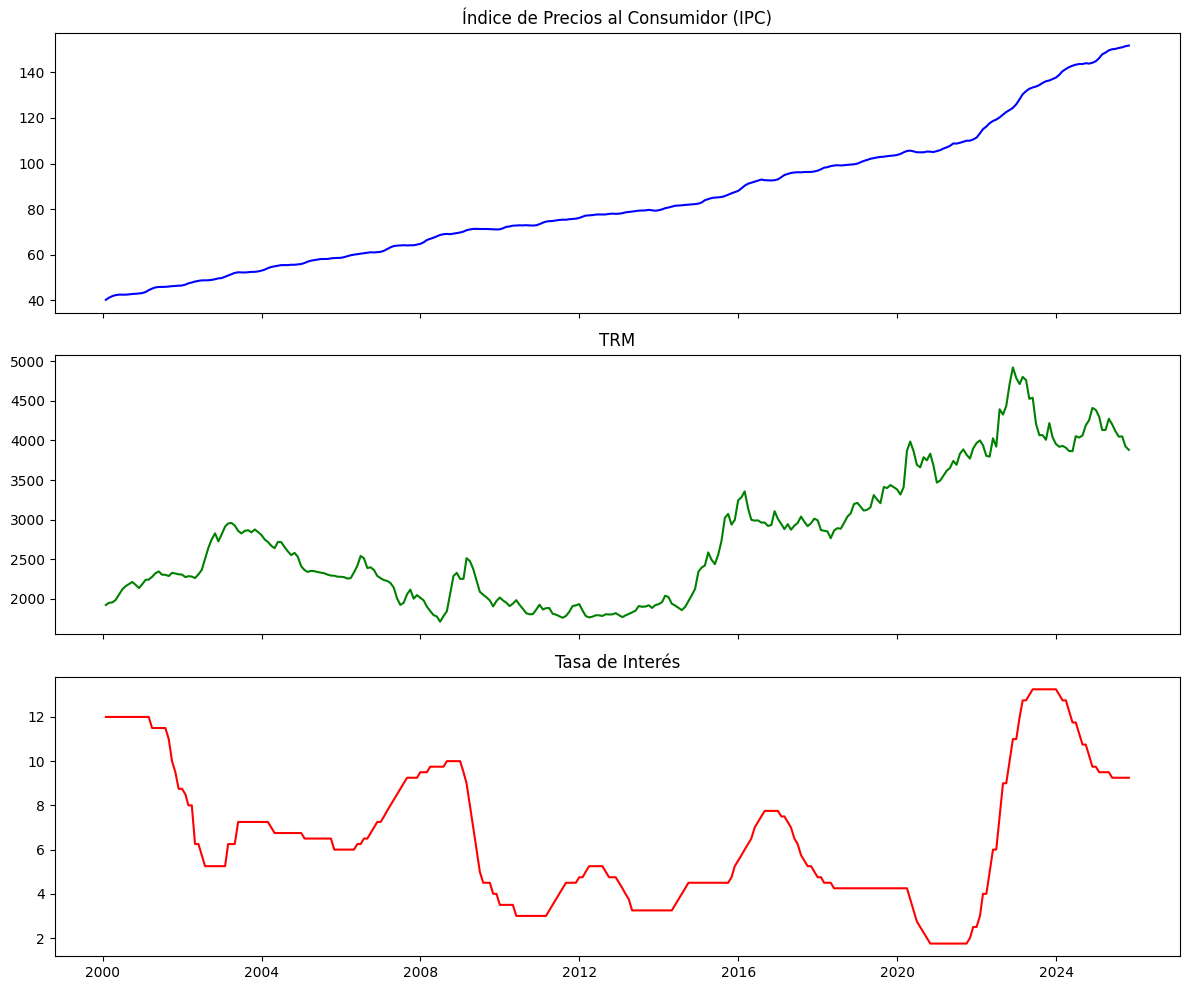

In [ ]:
# Visualización de Niveles
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
axes[0].plot(df.index, df['IPC'], label='IPC', color='blue')
axes[0].set_title('Índice de Precios al Consumidor (IPC)')
axes[1].plot(df.index, df['TRM'], label='TRM', color='green')
axes[1].set_title('TRM')
axes[2].plot(df.index, df['Tasa_interes'], label='Tasa Interés', color='red')
axes[2].set_title('Tasa de Interés')
plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

def test_stationarity(timeseries, significance_level=0.05):

    """
    Realiza la prueba de Dickey-Fuller Aumentada en una serie de tiempo dada y evalúa su estacionariedad.

    Parámetros:
    time_series (array-like): Los datos de la serie de tiempo a ser probados.
    significance_level (float): El nivel de significancia para la prueba (por defecto es 0.05).

    retorna:
    dict: Un diccionario que contiene el estadístico ADF, el valor p, los valores críticos y si la serie es estacionaria.

    """
    dftest = adfuller(timeseries)
    adf_statistic, p_value, used_lag, nobs, critical_values, icbest = dftest

    # Determinar si la serie es estacionaria basado en el valor p y el estadístico ADF
    is_stationary_p = p_value < significance_level
    is_stationary_adf = adf_statistic < critical_values['5%']  # Utiliza el valor crítico al 5%
    is_stationary = is_stationary_p and is_stationary_adf

    return {
        "ADF Statistic": adf_statistic,
        "p-value": p_value,
        "Critical Values": critical_values,
        "Is Stationary (p-value)": is_stationary_p,
        "Is Stationary (ADF)": is_stationary_adf,
        "Is Stationary (Both)": is_stationary
    }

In [ ]:
print("Test estacionariedad IPC: ", test_stationarity(df['IPC']))
print("Test estacionariedad Log_TRM: ", test_stationarity(df['TRM']))
print("Test estacionariedad Tasa Interés: ", test_stationarity(df['Tasa_interes']))

In [ ]:
# Transformaciones
# IPC: Se mantiene en niveles para visualización, pero se diferenciará para modelos.
# TRM: Logaritmo natural para estabilizar varianza.
df['Log_TRM'] = np.log(df['TRM'])
df['Log_IPC']=np.log(df['IPC'])
# Dataset base
df_model = df[['Log_IPC', 'Log_TRM', 'Tasa_interes']].dropna()

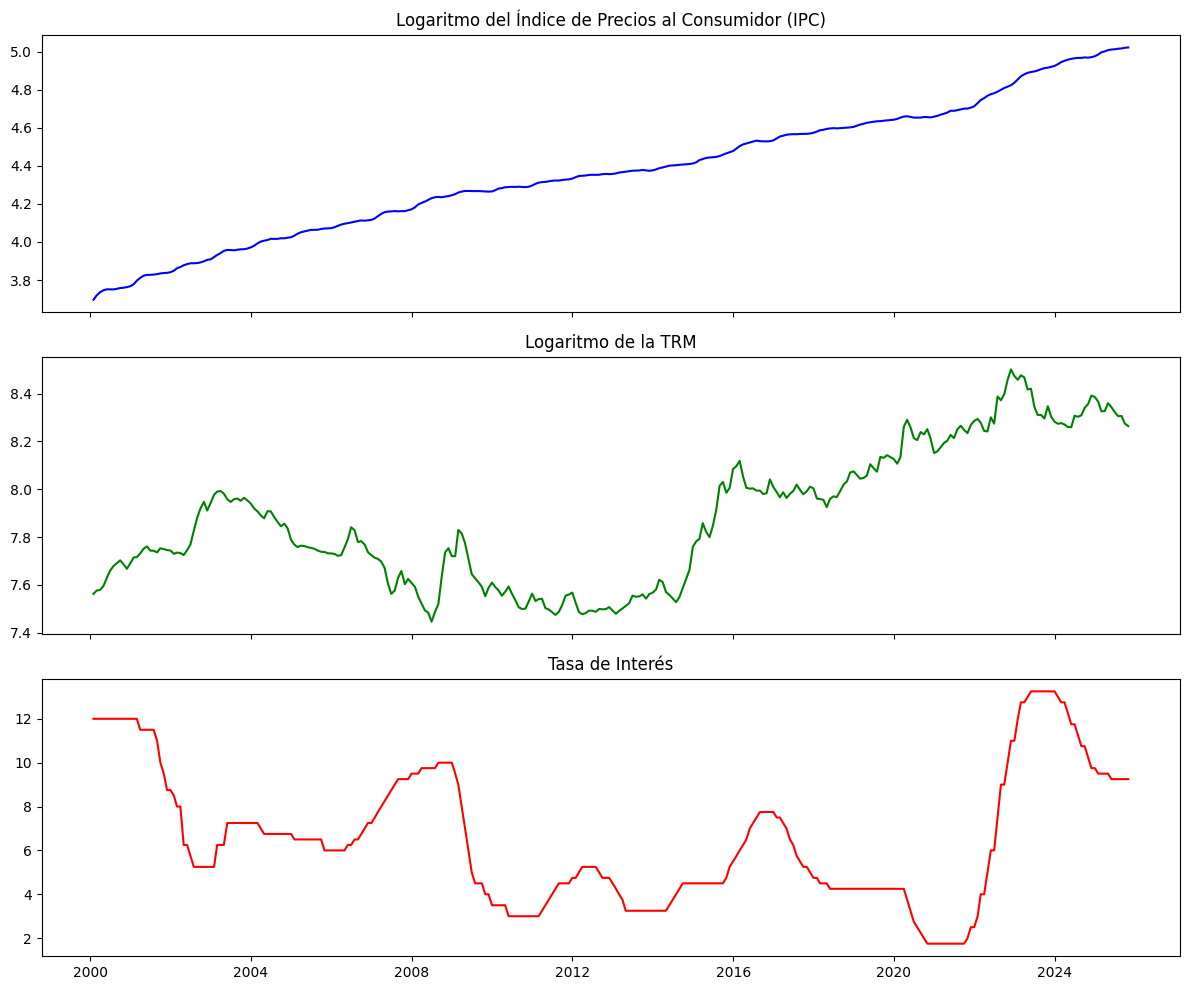

In [ ]:
# Visualización de Niveles
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
axes[0].plot(df_model.index, df_model['Log_IPC'], label='IPC (log)', color='blue')
axes[0].set_title('Logaritmo del Índice de Precios al Consumidor (IPC)')
axes[1].plot(df_model.index, df_model['Log_TRM'], label='Log TRM', color='green')
axes[1].set_title('Logaritmo de la TRM')
axes[2].plot(df_model.index, df_model['Tasa_interes'], label='Tasa Interés', color='red')
axes[2].set_title('Tasa de Interés')
plt.tight_layout()
plt.show()

# *Análisis STL*

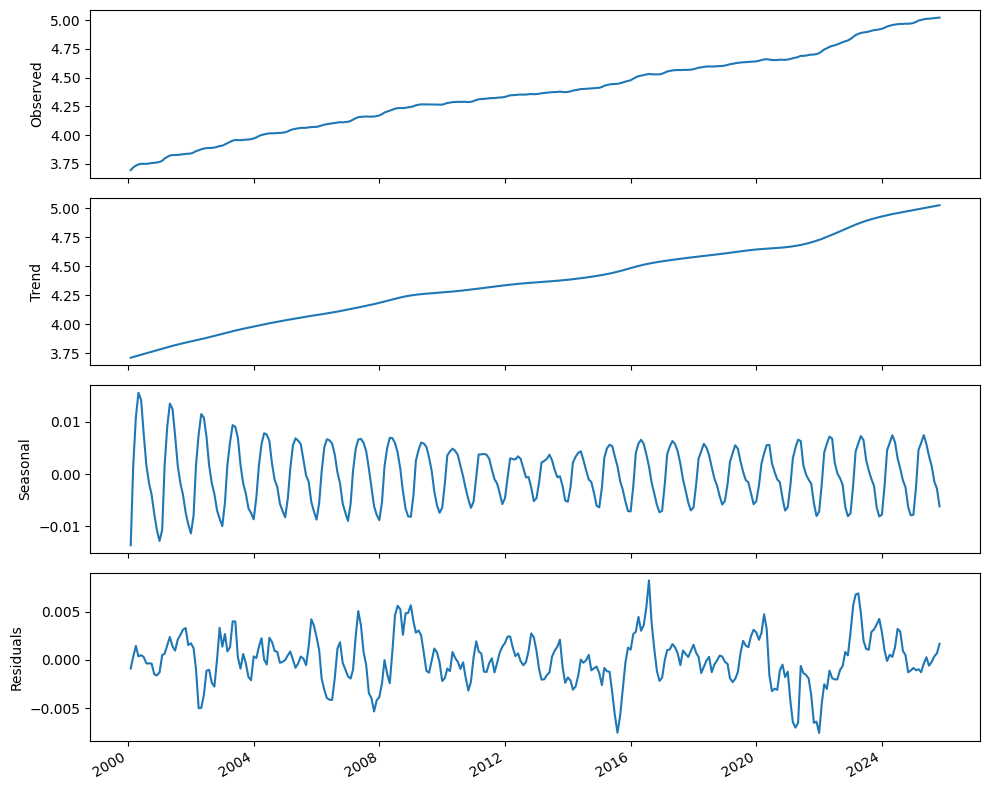

In [ ]:
decomposition = STL(df_model['Log_IPC'], period=12).fit()
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1, sharex=True, figsize=(10,8))
ax1.plot(decomposition.observed)
ax1.set_ylabel('Observed')
ax2.plot(decomposition.trend)
ax2.set_ylabel('Trend')
ax3.plot(decomposition.seasonal)
ax3.set_ylabel('Seasonal')
ax4.plot(decomposition.resid)
ax4.set_ylabel('Residuals')


fig.autofmt_xdate()
plt.tight_layout()

**Análisis de la Descomposición (STL)**

Se confirma visualmente que la serie Log_IPC NO es estacionaria.
Tendencia: la media de la serie cambia con el tiempo (en este caso, el IPC crece constantemente, lo cual es normal en economía por la inflación acumulada).
Estacionalidad: Hay patrones que se repiten periódicamente (por ejemplo, subidas de precios específicas en ciertos meses del año).
Consecuencia: Los modelos estadísticos clásicos (como ARIMA o VAR) asumen que la media y la varianza son constantes. Al ver estos patrones, sabemos de antemano que tendremos que diferenciar la serie para eliminar esa tendencia.

# *Test de estacionariedad*

In [ ]:
print("Test estacionariedad IPC: ", test_stationarity(df_model['Log_IPC']))
print("Test estacionariedad Log_TRM: ", test_stationarity(df_model['Log_TRM']))
print("Test estacionariedad Tasa Interés: ", test_stationarity(df_model['Tasa_interes']))

Test estacionariedad IPC:  {'ADF Statistic': np.float64(0.3612530684214709), 'p-value': np.float64(0.9799866652302078), 'Critical Values': {'1%': np.float64(-3.452867117291862), '5%': np.float64(-2.8714554160827745), '10%': np.float64(-2.5720532321867466)}, 'Is Stationary (p-value)': np.False_, 'Is Stationary (ADF)': np.False_, 'Is Stationary (Both)': np.False_}
Test estacionariedad Log_TRM:  {'ADF Statistic': np.float64(-1.1396699936987673), 'p-value': np.float64(0.69899560350736), 'Critical Values': {'1%': np.float64(-3.45176116018037), '5%': np.float64(-2.870970093607691), '10%': np.float64(-2.571794416006072)}, 'Is Stationary (p-value)': np.False_, 'Is Stationary (ADF)': np.False_, 'Is Stationary (Both)': np.False_}
Test estacionariedad Tasa Interés:  {'ADF Statistic': np.float64(-2.996903691650981), 'p-value': np.float64(0.035184570021913164), 'Critical Values': {'1%': np.float64(-3.4524113009049935), '5%': np.float64(-2.8712554127251764), '10%': np.float64(-2.571946570731871)}, '

**A. Log_IPC (Precios)**
p-value: 0.9799 (Muy alto, casi 1).
Conclusión: No es estacionaria.
Explicación: El valor es altísimo, lo que indica que la serie tiene una "raíz unitaria" muy fuerte. Es una serie que crece sistemáticamente y no vuelve a una media. Es obligatorio diferenciarla.


**B. Log_TRM (Tasa de Cambio)**
p-value: 0.6989 (Alto, > 0.05).
Conclusión: No es estacionaria.
Explicación: Aunque la TRM sube y baja, no se queda alrededor de un valor fijo a largo plazo en esta muestra.


**C. Tasa_interes (Política Monetaria)**
p-value: 0.0351 (Bajo, < 0.05).
Conclusión: SÍ es estacionaria.
Decisión de Modelado: Como esta serie ya es estacionaria, NO es necesario diferenciarla. Puedes usarla "en niveles" (tal cual está) dentro de tus modelos.

Primera diferencia de IPC y TRM

In [ ]:
# Diferenciación para Estacionariedad
df_stationary = df_model.copy()
df_stationary['Diff_Log_IPC'] = df_stationary['Log_IPC'].diff()
df_stationary['Diff_Log_TRM'] = df_stationary['Log_TRM'].diff()
df_stationary['Tasa_interes']= df_model['Tasa_interes']
df_stationary = df_stationary.dropna()

print("Test estacionariedad IPC: ", test_stationarity(df_stationary['Diff_Log_IPC']))
print("Test estacionariedad TRM: ", test_stationarity(df_stationary['Diff_Log_TRM']))


Test estacionariedad IPC:  {'ADF Statistic': np.float64(-3.1226257351810522), 'p-value': np.float64(0.02492346606116348), 'Critical Values': {'1%': np.float64(-3.452867117291862), '5%': np.float64(-2.8714554160827745), '10%': np.float64(-2.5720532321867466)}, 'Is Stationary (p-value)': np.True_, 'Is Stationary (ADF)': np.True_, 'Is Stationary (Both)': np.True_}
Test estacionariedad TRM:  {'ADF Statistic': np.float64(-11.369102482394808), 'p-value': np.float64(9.071738109229278e-21), 'Critical Values': {'1%': np.float64(-3.4518314994261337), '5%': np.float64(-2.8710009653519166), '10%': np.float64(-2.571810878948318)}, 'Is Stationary (p-value)': np.True_, 'Is Stationary (ADF)': np.True_, 'Is Stationary (Both)': np.True_}


In [ ]:
df_stationary.head()

,Log_IPC,Log_TRM,Tasa_interes,Diff_Log_IPC,Diff_Log_TRM
Fecha,,,,,
2000-02-29,3.719166,7.575913,12.0,0.022815,0.013975
2000-03-31,3.736002,7.578785,12.0,0.016835,0.002872
2000-04-30,3.745968,7.594265,12.0,0.009967,0.015481
2000-05-31,3.751150,7.628367,12.0,0.005181,0.034101
2000-06-30,3.750915,7.659252,12.0,-0.000235,0.030885


Al aplicar la primera diferencia a las series logarítmicas del IPC y la TRM, los nuevos tests de Dickey-Fuller confirman que el problema de raíz unitaria se ha solucionado exitosamente:

**Diff_Log_IPC:** El p-value descendió a 0.0249 (menor al umbral de 0.05). Esto indica que, aunque el nivel de precios sube siempre, la variación mensual (inflación) oscila alrededor de una media constante. La serie es ahora estacionaria.


**Diff_Log_TRM:** El resultado es extremadamente robusto, con un p-value cercano a cero (9.07e-21). La serie de variaciones del tipo de cambio es perfectamente estacionaria y muy estable en términos estadísticos.

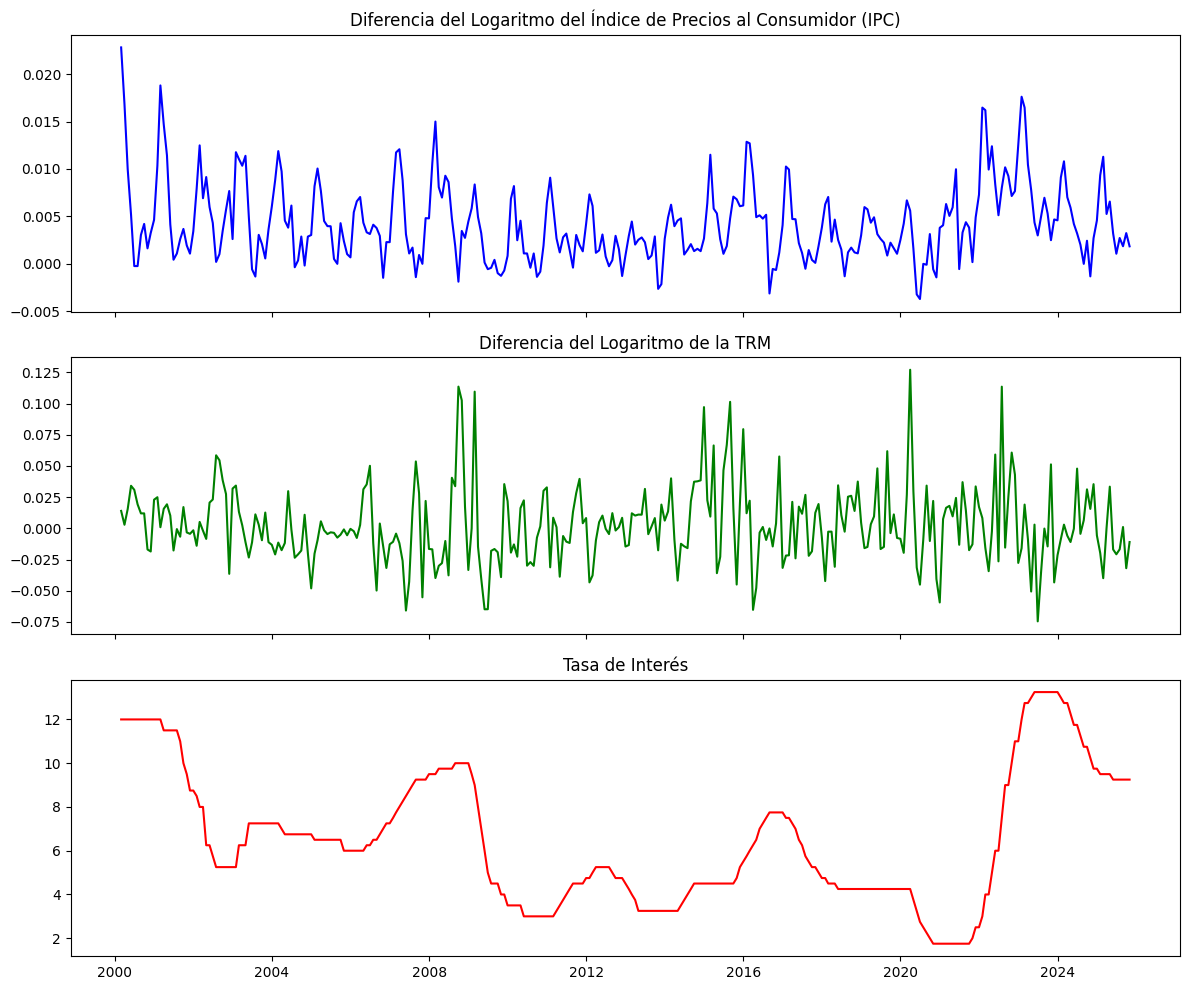

In [ ]:
# Visualización
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
axes[0].plot(df_stationary.index, df_stationary['Diff_Log_IPC'], label='Dif IPC (log)', color='blue')
axes[0].set_title('Diferencia del Logaritmo del Índice de Precios al Consumidor (IPC)')
axes[1].plot(df_stationary.index, df_stationary['Diff_Log_TRM'], label='Dif Log TRM', color='green')
axes[1].set_title('Diferencia del Logaritmo de la TRM')
axes[2].plot(df_stationary.index, df_stationary['Tasa_interes'], label='Tasa Interés', color='red')
axes[2].set_title('Tasa de Interés')
plt.tight_layout()
plt.show()

# *División del conjunto en entrenamiento y prueba*

In [ ]:
train_size = 280
train_st, test_st = df_model[:train_size], df_model[train_size:]
len(train_st), len(test_st)

(280, 30)

# *SARIMAX*

In [ ]:
target = df_model['Log_IPC']
exog = df_model[['Log_TRM', 'Tasa_interes']]

# Conjuto de entrenamiento y prueba con el 85% de la muestra
target_train = target.iloc[:280]
exog_train = exog.iloc[:280]
test_st=df_model[['Log_IPC','Log_TRM', 'Tasa_interes']].iloc[280:]


In [ ]:
def optimize_SARIMAX(endog: Union[pd.Series, list],
                     exog: Union[pd.Series, list],
                     order_list: list, d: int, D: int, s: int) -> pd.DataFrame:

    results = []

    for order in tqdm_notebook(order_list):
        try:
            model = SARIMAX(
                endog,
                exog,
                order=(order[0], d, order[1]),
                seasonal_order=(order[2], D, order[3], s),
                simple_differencing=False).fit(disp=False)
        except:
            continue

        aic = model.aic
        results.append([order, aic])

    result_df = pd.DataFrame(results)
    result_df.columns = ['(p,q,P,Q)', 'AIC']
    result_df = result_df.sort_values(by='AIC',
                                      ascending=True).reset_index(drop=True)

    return result_df

In [ ]:
p = range(0, 3, 1)
d = 1
q = range(0, 3, 1)
P = range(0, 3, 1)
D = 1
Q = range(0, 3, 1)
m = 4

parameters = product(p, q, P, Q)
parameters_list = list(parameters)

result_df = optimize_SARIMAX(target_train, exog_train, parameters_list, d, D, m)
result_df

  0%|          | 0/81 [00:00<?, ?it/s]

,"(p,q,P,Q)",AIC
0,"(2, 0, 2, 0)",-2459.685720
1,"(1, 0, 2, 0)",-2459.138531
2,"(0, 2, 2, 0)",-2457.128049
3,"(1, 2, 2, 0)",-2456.361733
4,"(2, 0, 2, 2)",-2454.916861
...,...,...
76,"(0, 2, 0, 0)",-2220.764219
77,"(0, 1, 0, 0)",-2220.124239
78,"(1, 0, 0, 0)",-2217.577841
79,"(0, 0, 1, 0)",-2112.930336


Para determinar la estructura óptima del modelo, se utilizó un criterio de información de Akaike (AIC). La búsqueda de hiperparámetros indicó que los modelos con componentes autoregresivos de orden 2 (p=2) y componentes estacionales (P=2) minimizaban la pérdida de información, arrojando valores de AIC cercanos a -2460.

Finalmente, se estimó un modelo SARIMAX(2, 1, 0)x(2, 1, 0, 4). Esta especificación incluye una diferenciación (d=1) para corregir la no estacionariedad detectada previamente en el IPC, y componentes estacionales trimestrales (s=4), lo cual es consistente con la naturaleza económica de los precios.

                                     SARIMAX Results                                     
Dep. Variable:                           Log_IPC   No. Observations:                  280
Model:             SARIMAX(2, 1, 0)x(2, 1, 0, 4)   Log Likelihood                1236.843
Date:                           Wed, 26 Nov 2025   AIC                          -2459.686
Time:                                   02:13:43   BIC                          -2434.368
Sample:                               01-31-2000   HQIC                         -2449.525
                                    - 04-30-2023                                         
Covariance Type:                             opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Log_TRM         -0.0022      0.004     -0.528      0.598      -0.011       0.006
Tasa_interes     0.0007      0.000   

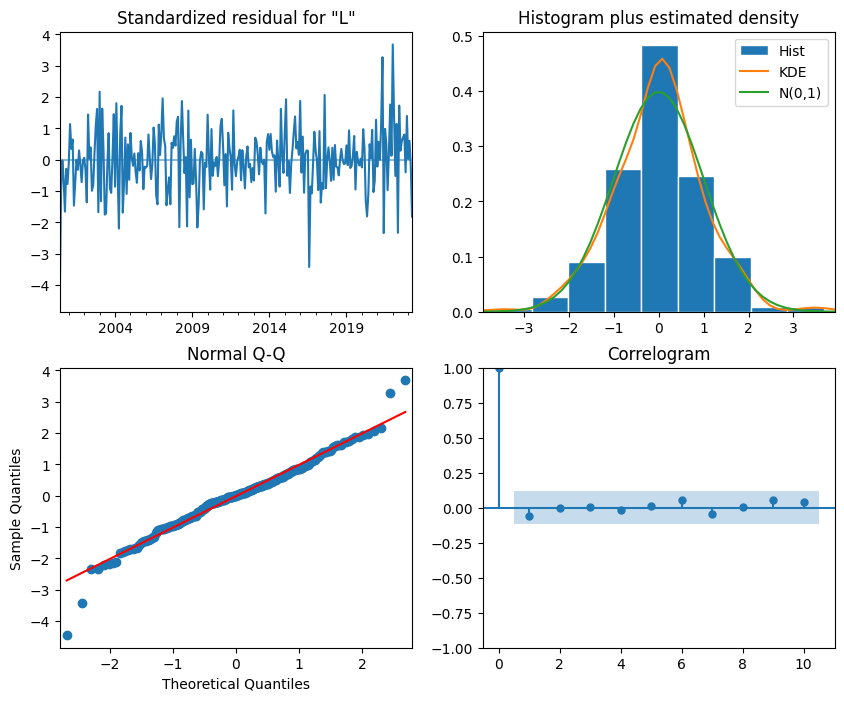

In [ ]:
SARIMAX_model = SARIMAX(target_train, exog_train, order=(2,1,0), seasonal_order=(2,1,0,4), simple_differencing=False)
SARIMAX_model_fit = SARIMAX_model.fit(disp=False)

print(SARIMAX_model_fit.summary())
SARIMAX_model_fit.plot_diagnostics(figsize=(10,8));

Variables Exógenas: Ni la TRM (p-value=0.598) ni la Tasa de Interés (p-value=0.145) resultaron estadísticamente significativas al 5% dentro de este modelo específico. Esto sugiere que la inercia inflacionaria (el comportamiento pasado del propio IPC) es tan fuerte que absorbe el poder explicativo de las variables externas en el corto plazo.

Componentes Autoregresivos: Por el contrario, los términos autoregresivos (ar.L1) y estacionales (ar.S.L4, ar.S.L8) tienen una significancia estadística absoluta (p-value=0.000). Esto confirma que la mejor forma de predecir el IPC futuro es observando su propia historia reciente y sus patrones estacionales.

Ausencia de Autocorrelación: La prueba de Ljung-Box arroja una probabilidad de 0.33 (> 0.05), lo que indica que los residuos se comportan como "ruido blanco"; es decir, el modelo ha capturado exitosamente toda la información temporal y no quedan patrones ocultos.

Homocedasticidad: La prueba de Heterocedasticidad (Prob(H)=0.96) confirma que la varianza de los errores es constante a lo largo del tiempo, lo cual es ideal para la estabilidad de los pronósticos.

Normalidad: La única debilidad se encuentra en la prueba de Jarque-Bera (Prob=0.00), indicando que los errores no siguen una distribución perfectamente normal (probablemente debido a eventos atípicos o "colas pesadas" en la economía), aunque esto es común en series financieras y no invalida el modelo dado el cumplimiento de los otros supuestos.

In [ ]:
def recursive_forecast_SARIMAX(endog: Union[pd.Series, list],
                               exog: Union[pd.Series, list],
                               train_len: int, horizon: int, window: int) -> list:

      pred_SARIMAX = []
      total_len = train_len + horizon

      for i in range(train_len, total_len, window):
          model = SARIMAX(endog[:i], exog[:i], order=(2,1,0),
                          seasonal_order=(2,1,0,4), simple_differencing=False)
          res = model.fit(disp=False)

          predictions = res.get_prediction(start=i, end=i+window-1, exog=exog.iloc[i:i+window])

          oos_pred = predictions.predicted_mean
          pred_SARIMAX.extend(oos_pred)

      return pred_SARIMAX

In [ ]:
TRAIN_LEN = len(target_train)
HORIZON = len(test_st)
WINDOW = 1
pred_SARIMAX = recursive_forecast_SARIMAX(target, exog, TRAIN_LEN, HORIZON, WINDOW)

fechas = test_st.index
st_pred_SARIMAX = pd.Series(pred_SARIMAX[:len(fechas)], index=fechas)

mse_SARIMAX = mean_squared_error(test_st['Log_IPC'], st_pred_SARIMAX)
rmse_SARIMAX = np.sqrt(mse_SARIMAX)

r2_SARIMAX = r2_score(test_st['Log_IPC'], st_pred_SARIMAX)


mse_SARIMAX, rmse_SARIMAX, r2_SARIMAX

(4.088613161622636e-06, np.float64(0.0020220319388235776), 0.997454899500635)

El modelo presenta un ajuste sobresaliente sobre los datos de prueba:

R² (0.997): El modelo explica el 99.7% de la variabilidad del Logaritmo del IPC, lo cual demuestra un ajuste casi perfecto a la tendencia de los datos.

RMSE (0.0020): El error cuadrático medio es extremadamente bajo. Dado que estamos trabajando en escala logarítmica, un error de 0.0020 se traduce aproximadamente en una desviación del 0.2% en el nivel de precios real, lo cual indica una precisión predictiva muy alta para el horizonte evaluado.



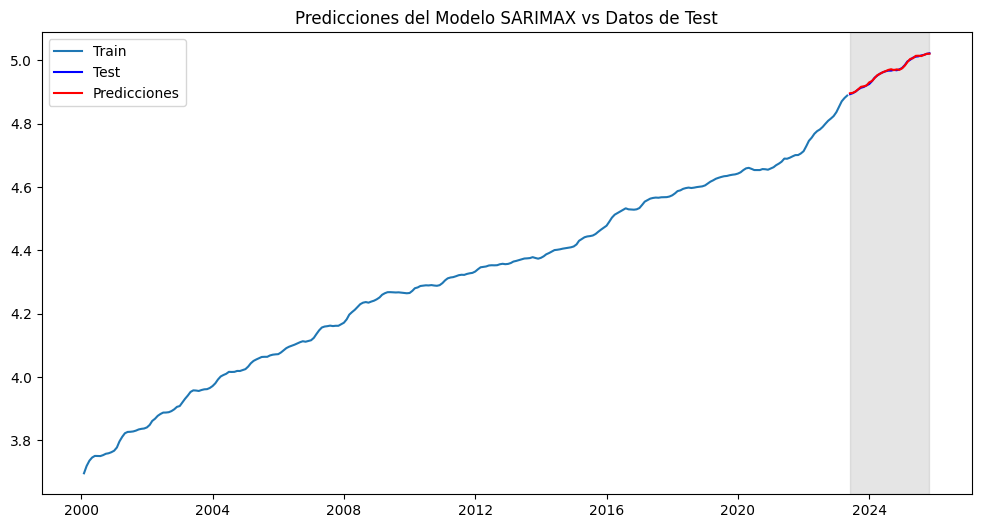

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(train_st['Log_IPC'],label='Train')
ax.plot(test_st['Log_IPC'], label='Test', color='blue')
ax.plot(st_pred_SARIMAX, label='Predicciones', color='red')
ax.legend(loc='best')
ax.set_title('Predicciones del Modelo SARIMAX vs Datos de Test')


fecha_inicio = test_st.index[0]
fecha_fin = test_st.index[-1]
ax.axvspan(fecha_inicio, fecha_fin, color='#808080', alpha=0.2)

# *MODELO VAR*

In [ ]:
def optimize_VAR(endog: Union[pd.Series, list]) -> pd.DataFrame:

    results = []

    for i in tqdm_notebook(range(15)):
        try:
            model = VARMAX(endog, order=(i, 0)).fit(display=False)
        except:
            continue

        aic = model.aic
        results.append([i, aic])

    result_df = pd.DataFrame(results)
    result_df.columns = ['p', 'AIC']

    result_df = result_df.sort_values(by='AIC', ascending=True).reset_index(drop=True)

    return result_df

In [ ]:
endog = df_model[['Log_IPC', 'Log_TRM', "Tasa_interes"]]

endog_diff = df_stationary[['Diff_Log_IPC', 'Diff_Log_TRM', 'Tasa_interes']]

train= endog_diff.iloc[:int(len(target))]

train = endog_diff[:280]
test = endog_diff[280:]

result_df = optimize_VAR(train)
result_df

  0%|          | 0/15 [00:00<?, ?it/s]

,p,AIC
0,12,-3694.794132
1,13,-3687.546522
2,14,-3681.935059
3,11,-3675.461020
4,9,-3646.203627
5,10,-3644.974546
6,8,-3639.649581
7,6,-3632.515616
8,5,-3630.635423
9,7,-3630.596911


Para determinar la estructura dinámica del sistema multivariado, se evaluaron modelos VAR iterando la cantidad de rezagos (lags) desde 1 hasta 15. El criterio de selección fue minimizar el Criterio de Información de Akaike (AIC).

Resultado: El modelo óptimo se alcanzó con 12 rezagos (p=12), obteniendo el AIC más bajo de -3694.79.

Interpretación Económica: El hecho de que el modelo requiera 12 rezagos indica que la dependencia temporal de las variables abarca un ciclo anual completo. Para predecir la inflación, la tasa de cambio y la tasa de interés hoy, el modelo necesita "recordar" lo que sucedió durante los últimos 12 meses. Esto es consistente con la inercia de las variables macroeconómicas mensuales.

In [ ]:
def granger_causality_matrix(data, variables, maxlag=12, test='ssr_ftest'):
    """
    Calcula los p-valores de la prueba de causalidad de Granger para cada rezago.
    """
    df_results = pd.DataFrame(columns=['Lag', 'Causa', 'Efecto', 'P-Value'])

    for lag in range(1, maxlag + 1):
        # Test: ¿La segunda variable causa a la primera? (Ojo al orden en statsmodels: (y, x) -> x causa y?)
        # grangercausalitytests toma (target, predictor)

        # Caso 1: TRM -> IPC
        res_trm = grangercausalitytests(data[[variables[0], variables[1]]], maxlag=[lag], verbose=False)
        p_value_trm = res_trm[lag][0][test][1]

        # Caso 2: Tasa Interés -> IPC
        res_tasa = grangercausalitytests(data[[variables[0], variables[2]]], maxlag=[lag], verbose=False)
        p_value_tasa = res_tasa[lag][0][test][1]

        df_results = pd.concat([df_results, pd.DataFrame({
            'Lag': [lag, lag],
            'Causa': [variables[1], variables[2]],
            'Efecto': [variables[0], variables[0]],
            'P-Value': [p_value_trm, p_value_tasa]
        })], ignore_index=True)

    return df_results

# Definimos las variables: [Target, Predictor1, Predictor2]
# Target: Diff_Log_IPC
vars_to_test = ['Diff_Log_IPC', 'Diff_Log_TRM', 'Tasa_interes']

# Ejecutamos sobre el conjunto de entrenamiento
granger_results = granger_causality_matrix(train, vars_to_test, maxlag=12)

# Filtramos para ver solo donde hay causalidad significativa (p < 0.05)
print("Resultados significativos (Causalidad detectada):")
print(granger_results[granger_results['P-Value'] < 0.05])

# Mostrar tabla completa pivotada para facilitar lectura
print("\nTabla completa de P-Values:")
print(granger_results.pivot(index='Lag', columns='Causa', values='P-Value'))

Resultados significativos (Causalidad detectada):
   Lag         Causa        Efecto   P-Value
3    2  Tasa_interes  Diff_Log_IPC  0.021006
5    3  Tasa_interes  Diff_Log_IPC  0.000450
7    4  Tasa_interes  Diff_Log_IPC  0.000442
9    5  Tasa_interes  Diff_Log_IPC  0.000044
11   6  Tasa_interes  Diff_Log_IPC  0.000009
13   7  Tasa_interes  Diff_Log_IPC  0.000002
15   8  Tasa_interes  Diff_Log_IPC  0.000003
17   9  Tasa_interes  Diff_Log_IPC  0.000076
19  10  Tasa_interes  Diff_Log_IPC  0.000461
21  11  Tasa_interes  Diff_Log_IPC  0.003239
22  12  Diff_Log_TRM  Diff_Log_IPC  0.028135
23  12  Tasa_interes  Diff_Log_IPC  0.000061

Tabla completa de P-Values:
Causa  Diff_Log_TRM  Tasa_interes
Lag                              
1          0.098175      0.353782
2          0.239259      0.021006
3          0.424808      0.000450
4          0.512641      0.000442
5          0.159103      0.000044
6          0.124068      0.000009
7          0.217953      0.000002
8          0.258418      0.000

Efecto de la Tasa de Interés sobre la Inflación (Tasa_interes
→
→ Diff_Log_IPC):

Se detectó una causalidad altamente significativa a partir del segundo mes (rezago 2), con p-valores que se vuelven extremadamente pequeños desde el rezago 3 hasta el 12.

Conclusión: Esto confirma empíricamente la efectividad del mecanismo de transmisión de la política monetaria. Las decisiones del Banco de la República de subir o bajar tasas no afectan la inflación inmediatamente (en el mes 1 no es significativo), sino que tardan entre 2 y 3 meses en comenzar a impactar los precios, manteniendo su efecto durante todo el año.

Efecto de la TRM sobre la Inflación (Diff_Log_TRM
→
→ Diff_Log_IPC):

A diferencia de la tasa de interés, la tasa de cambio NO muestra causalidad significativa en el corto plazo (rezagos 1 al 11 tienen p-valores altos). Solo aparece una significancia leve en el rezago 12 (p=0.028)

Conclusión: El pass-through (el traspaso de la devaluación a la inflación) parece ser débil o muy lento en este periodo de análisis. Los movimientos del dólar no se traducen inmediatamente en cambios en el IPC general.

                                          Statespace Model Results                                          
Dep. Variable:     ['Diff_Log_IPC', 'Diff_Log_TRM', 'Tasa_interes']   No. Observations:                  280
Model:                                                      VAR(12)   Log Likelihood                1964.397
                                                        + intercept   AIC                          -3694.794
Date:                                              Wed, 26 Nov 2025   BIC                          -3269.524
Time:                                                      03:06:53   HQIC                         -3524.218
Sample:                                                  02-29-2000                                         
                                                       - 05-31-2023                                         
Covariance Type:                                                opg                                         
Ljung-Box (L1) (Q):

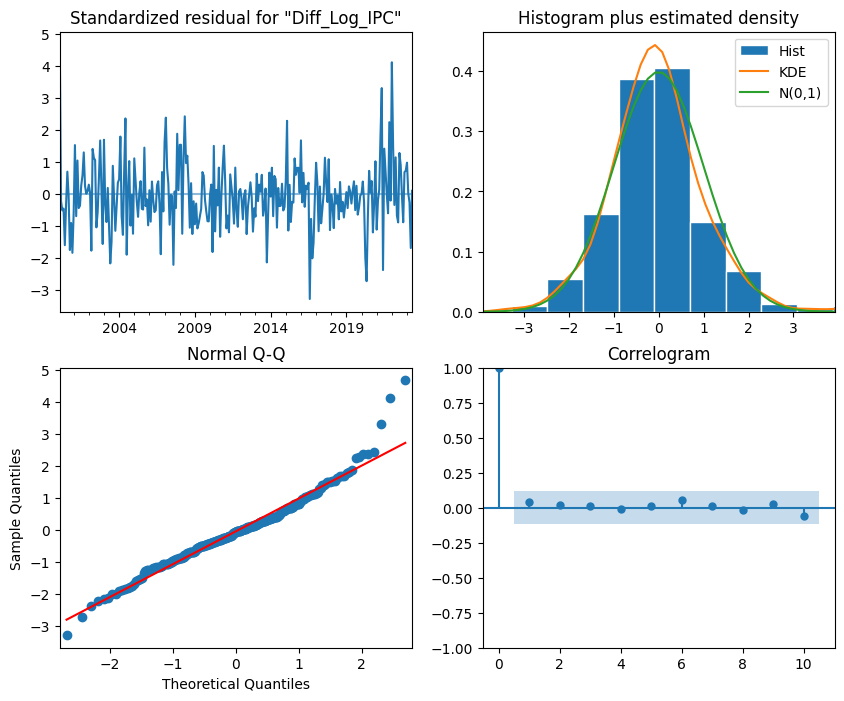

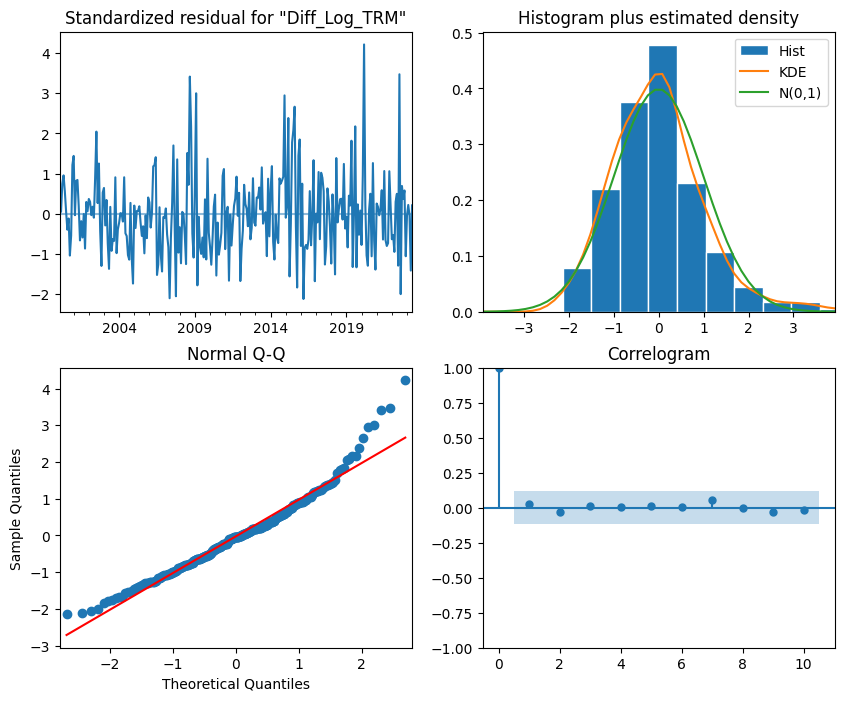

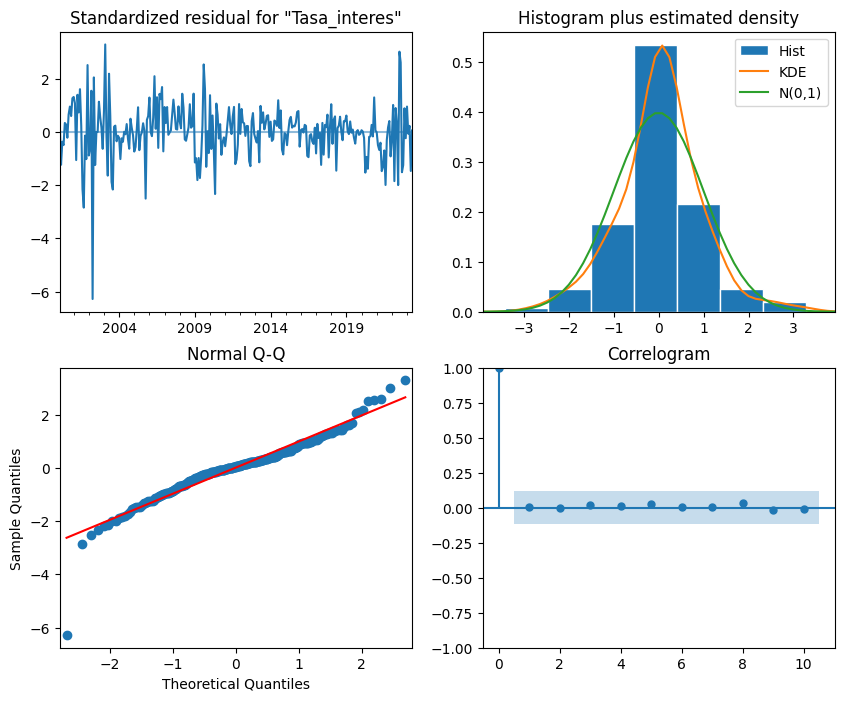

In [ ]:
VAR_model = VARMAX(train, order=(12,0))
VAR_model_fit = VAR_model.fit(disp=False)

print(VAR_model_fit.summary())
VAR_model_fit.plot_diagnostics(figsize=(10,8), variable=0);
VAR_model_fit.plot_diagnostics(figsize=(10,8), variable=1);
VAR_model_fit.plot_diagnostics(figsize=(10,8), variable=2);

A. Ecuación de la Inflación (Diff_Log_IPC)
Esta es la ecuación más importante para nuestro objetivo de pronóstico. Los resultados muestran:

Inercia Inflacionaria: El coeficiente del primer rezago de la propia inflación (L1.Diff_Log_IPC) es 0.55 y altamente significativo (p=0.000). Esto confirma que la inflación de hoy depende fuertemente de la inflación del mes pasado.
Efecto de la Tasa de Interés: Aunque individualmente los coeficientes rezagados de la tasa de interés no parecen significativos uno por uno (debido a la multicolinealidad entre rezagos cercanos), la prueba de causalidad de Granger que vimos antes confirmó que, en conjunto, sí tienen un efecto retardado importante.
Efecto de la TRM: Los coeficientes de la TRM no son significativos individualmente en la mayoría de los rezagos, lo que refuerza la idea de un pass-through débil o muy diluido en el tiempo.

B. Ecuación de la Tasa de Interés (Tasa_interes)
Esta ecuación nos dice cómo reacciona el Banco de la República (regla de Taylor implícita):

Reacción a la Inflación: El coeficiente L1.Diff_Log_IPC es positivo (18.32) y significativo (p=0.026). Esto indica que el Banco Central reacciona subiendo las tasas cuando la inflación del mes anterior aumenta, cumpliendo su mandato constitucional.
Persistencia de la Tasa: El coeficiente L1.Tasa_interes es 1.13 (p=0.000), mostrando que la política monetaria es muy gradual; las tasas de hoy dependen casi totalmente de las tasas de ayer.

C. Ecuación de la TRM (Diff_Log_TRM)
Al revisar los coeficientes para la ecuación de la tasa de cambio, encontramos un comportamiento muy particular que respalda la teoría financiera sobre los tipos de cambio:

Autoregresión Significativa: El único predictor consistente de la TRM hoy es la TRM de ayer. El coeficiente L1.Diff_Log_TRM es 0.3151 y altamente significativo (p=0.000). Esto indica que la tasa de cambio tiene "memoria" de corto plazo (momentum); si subió el mes pasado, tiende a seguir subiendo este mes.



**Diagnóstico de los Residuos del VAR**

La validación del modelo muestra resultados mixtos pero aceptables para fines de pronóstico:

Autocorrelación (Test Ljung-Box):
Para la ecuación de Inflación (Diff_Log_IPC), el p-valor es 0.46, lo que indica que NO hay autocorrelación en los residuos. El modelo capturó bien la dinámica temporal de los precios.
Para la TRM y la Tasa de Interés, los p-valores también son altos (0.68 y 0.96), validando el modelo en todas sus dimensiones.
Normalidad (Test Jarque-Bera):
Los p-valores son 0.00 para las tres ecuaciones, rechazando la hipótesis de normalidad. Esto es típico en series financieras que tienen "colas pesadas" (eventos extremos más frecuentes de lo normal), pero no invalida el uso del modelo para pronósticos puntuales.

In [ ]:
def rolling_forecast_VAR(df: pd.DataFrame, train_len: int, horizon: int, window: int, order: tuple) -> pd.DataFrame:

    total_len = train_len + horizon

    # Listas para almacenar predicciones de tus 3 variables
    pred_IPC = []
    pred_TRM = []
    pred_Tasa = []

    print(f"Iniciando Rolling Forecast con orden {order}...")

    for i in tqdm_notebook(range(train_len, total_len, window)):
        try:
            # Ajustar modelo con datos hasta el punto i
            model = VARMAX(df[:i], order=order, trend='c') # trend='c' consistente con celda anterior
            res = model.fit(disp=False)

            # Predecir el siguiente paso (window)
            predictions = res.get_prediction(start=i, end=i + window - 1)
            predicted_mean = predictions.predicted_mean

            # Guardar predicciones usando los nombres correctos de TUS columnas
            pred_IPC.extend(predicted_mean['Diff_Log_IPC'])
            pred_TRM.extend(predicted_mean['Diff_Log_TRM'])
            pred_Tasa.extend(predicted_mean['Tasa_interes'])

        except Exception as e:
            print(f"Error en índice {i}: {e}")
            # En caso de error, podrías repetir el último valor o llenar con NaN
            continue

    predictions_df = pd.DataFrame({
        'Diff_Log_IPC': pred_IPC,
        'Diff_Log_TRM': pred_TRM,
        'Tasa_interes': pred_Tasa
    })

    # Asignar índice de fechas correcto correspondiente al periodo de test
    predictions_df.index = df.index[train_len : train_len + len(predictions_df)]

    return predictions_df

In [ ]:
TRAIN_LEN = len(train)
HORIZON = len(test)
WINDOW = 1
ORDER = (12, 0) # Usamos el orden p=12 que definiste en celdas anteriores

# Ejecutar el rolling forecast con la función corregida
pred_diff_VAR = rolling_forecast_VAR(endog_diff, TRAIN_LEN, HORIZON, WINDOW, ORDER)

# Mostrar las primeras filas de las predicciones
print(pred_diff_VAR.head())

Iniciando Rolling Forecast con orden (12, 0)...


  0%|          | 0/29 [00:00<?, ?it/s]

            Diff_Log_IPC  Diff_Log_TRM  Tasa_interes
Fecha                                               
2023-06-30      0.004617     -0.015949     13.199628
2023-07-31      0.002300     -0.024990     13.481255
2023-08-31      0.006752      0.017816     13.406178
2023-09-30      0.005796     -0.004196     13.010973
2023-10-31      0.003603     -0.018265     13.319393


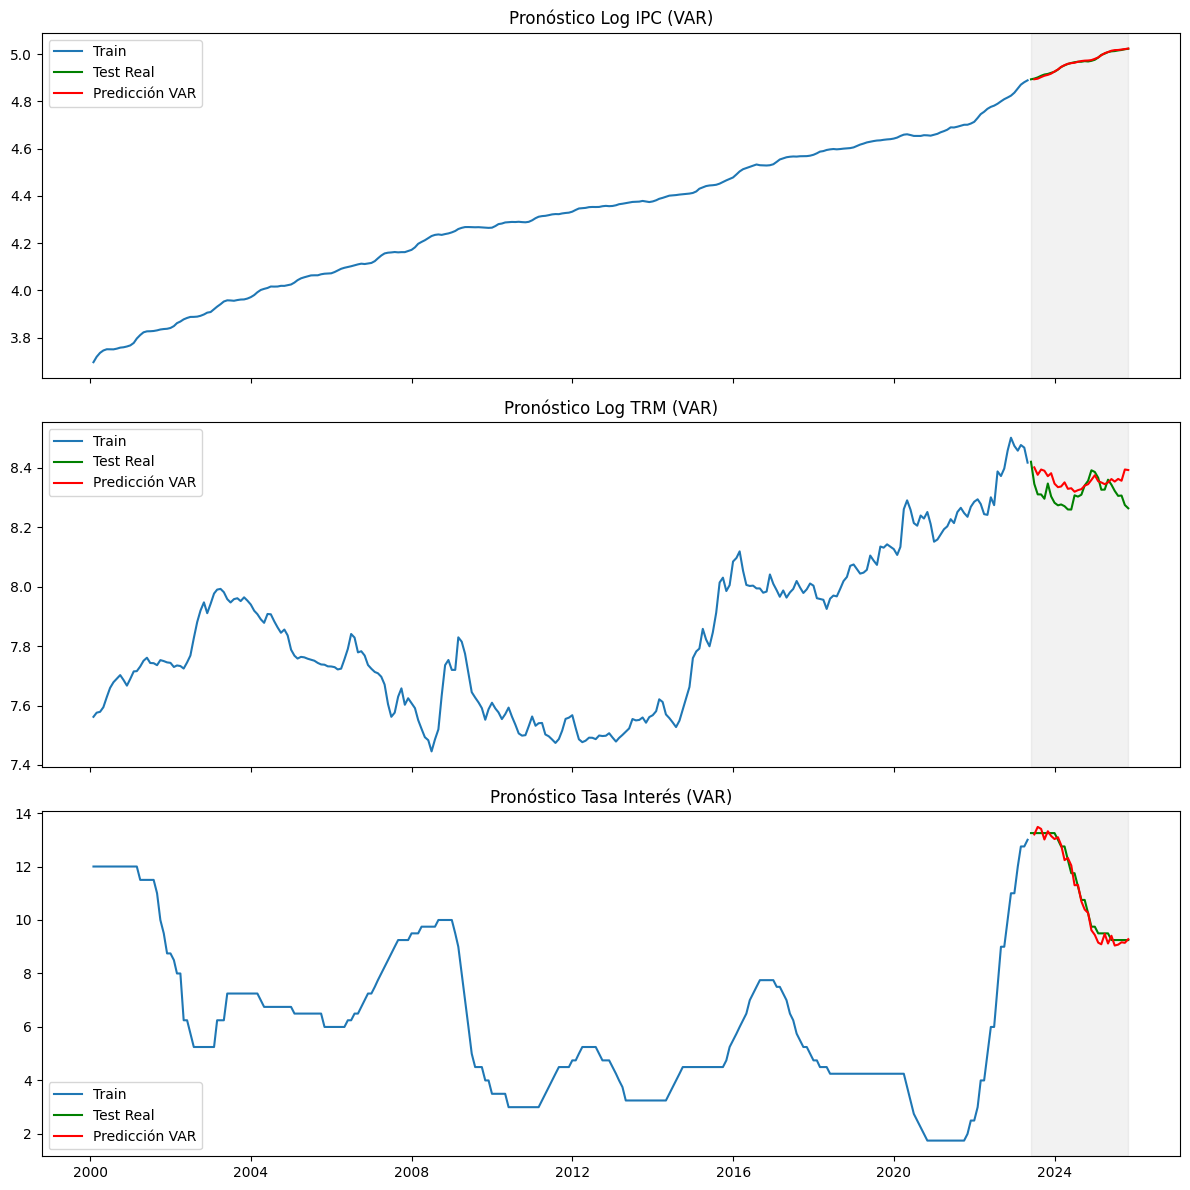

Métricas VAR - Log IPC (Evaluado en 29 periodos):
MSE: 0.00001
RMSE: 0.00281
R2: 0.99468


In [ ]:
# 1. Recuperar el último valor real del entrenamiento (en niveles logarítmicos)
# Usamos df_model que tiene los datos originales en niveles (Log)
last_log_ipc_train = df_model['Log_IPC'].iloc[TRAIN_LEN - 1]
last_log_trm_train = df_model['Log_TRM'].iloc[TRAIN_LEN - 1]

# 2. Reconstrucción: Acumular las diferencias predichas y sumar al último valor base
pred_levels_VAR = pd.DataFrame(index=pred_diff_VAR.index)

# Para las series diferenciadas, hacemos suma acumulativa + valor inicial
pred_levels_VAR['Log_IPC'] = last_log_ipc_train + pred_diff_VAR['Diff_Log_IPC'].cumsum()
pred_levels_VAR['Log_TRM'] = last_log_trm_train + pred_diff_VAR['Diff_Log_TRM'].cumsum()

# Para la tasa de interés, usamos la predicción directa (no se diferenció)
pred_levels_VAR['Tasa_interes'] = pred_diff_VAR['Tasa_interes']

# 3. Obtener datos reales de Test en niveles para comparar
test_levels = df_model.iloc[TRAIN_LEN:]

# 4. Graficar
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

# Gráfica IPC
axes[0].plot(df_model.index[:TRAIN_LEN], df_model['Log_IPC'][:TRAIN_LEN], label='Train')
axes[0].plot(test_levels.index, test_levels['Log_IPC'], label='Test Real', color='green')
axes[0].plot(pred_levels_VAR.index, pred_levels_VAR['Log_IPC'], label='Predicción VAR', color='red')
axes[0].set_title('Pronóstico Log IPC (VAR)')
axes[0].legend()

# Gráfica TRM
axes[1].plot(df_model.index[:TRAIN_LEN], df_model['Log_TRM'][:TRAIN_LEN], label='Train')
axes[1].plot(test_levels.index, test_levels['Log_TRM'], label='Test Real', color='green')
axes[1].plot(pred_levels_VAR.index, pred_levels_VAR['Log_TRM'], label='Predicción VAR', color='red')
axes[1].set_title('Pronóstico Log TRM (VAR)')
axes[1].legend()

# Gráfica Tasa Interés
axes[2].plot(df_model.index[:TRAIN_LEN], df_model['Tasa_interes'][:TRAIN_LEN], label='Train')
axes[2].plot(test_levels.index, test_levels['Tasa_interes'], label='Test Real', color='green')
axes[2].plot(pred_levels_VAR.index, pred_levels_VAR['Tasa_interes'], label='Predicción VAR', color='red')
axes[2].set_title('Pronóstico Tasa Interés (VAR)')
axes[2].legend()

# Zona gris para el periodo de test
fecha_inicio = test_levels.index[0]
fecha_fin = test_levels.index[-1]
for ax in axes:
    ax.axvspan(fecha_inicio, fecha_fin, color='#808080', alpha=0.1)

plt.tight_layout()
plt.show()

# 5. Calcular métricas de desempeño para IPC (CORREGIDO POR ALINEACIÓN DE ÍNDICES)

# Encontramos las fechas comunes entre los datos reales y las predicciones
common_dates = test_levels.index.intersection(pred_levels_VAR.index)

# Filtramos ambos dataframes usando solo esas fechas comunes
y_true_aligned = test_levels.loc[common_dates, 'Log_IPC']
y_pred_aligned = pred_levels_VAR.loc[common_dates, 'Log_IPC']

mse_VAR = mean_squared_error(y_true_aligned, y_pred_aligned)
rmse_VAR = np.sqrt(mse_VAR)
r2_VAR = r2_score(y_true_aligned, y_pred_aligned)

print(f"Métricas VAR - Log IPC (Evaluado en {len(common_dates)} periodos):")
print(f"MSE: {mse_VAR:.5f}")
print(f"RMSE: {rmse_VAR:.5f}")
print(f"R2: {r2_VAR:.5f}")

Error Cuadrático Medio (MSE = 0.00001): El error promedio al cuadrado es prácticamente cero. Esto indica que la varianza del error de pronóstico es mínima.

Raíz del Error Cuadrático Medio (RMSE = 0.00281):
Esta es la métrica más intuitiva porque está en las mismas unidades que la variable (Logaritmo del IPC).

Un error de 0.0028 en escala logarítmica equivale aproximadamente a un error del 0.28% en el nivel de precios real.
Interpretación: Si el IPC real fuera de 100, el modelo pronosticaría entre 99.72 y 100.28. Es una precisión extremadamente alta para un pronóstico económico a casi 3 años vista.

Coeficiente de Determinación (R2= 0.99468):
El modelo es capaz de explicar el 99.47% de la variación observada en los precios durante el periodo de prueba.
Esto confirma que la estructura dinámica capturada (inercia propia + efecto rezagado de tasas de interés) es suficiente para replicar casi a la perfección la trayectoria de la inflación en Colombia.

Evaluando modelos sobre 29 periodos comunes (fechas perfectamente alineadas).

--- Tabla Comparativa de Desempeño ---


,Modelo,MSE,RMSE,MAE,R2
0,SARIMAX,0.000004,0.001989,0.001563,0.997338
1,VAR,0.000008,0.002810,0.002294,0.994684


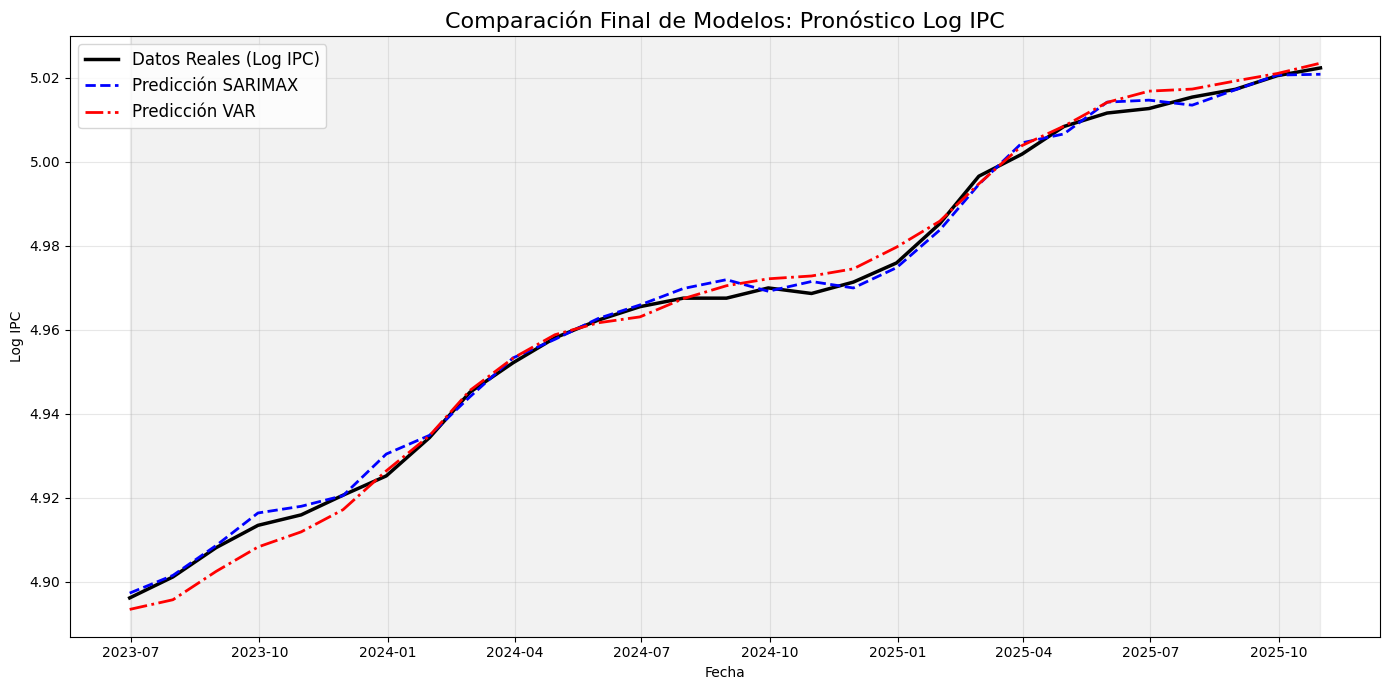

In [ ]:
# ---------------------------------------------------------
# 1. CONSOLIDACIÓN Y ALINEACIÓN DE DATOS
# ---------------------------------------------------------

# Creamos un DataFrame maestro usando el índice del conjunto de test original
# Esto nos sirve de base para alinear todas las series por fecha
df_comparison = pd.DataFrame(index=test_levels.index)

# Asignamos las columnas. Pandas alineará automáticamente por las fechas (índice).
# Si alguna fecha no tiene predicción en alguno de los modelos, quedará como NaN.
df_comparison['Real'] = test_levels['Log_IPC']
df_comparison['SARIMAX'] = st_pred_SARIMAX
df_comparison['VAR'] = pred_levels_VAR['Log_IPC']

# --- IMPORTANTE: Si tienes el modelo de Regresión Lineal, descomenta y ajusta la siguiente línea: ---
# Asegúrate de que 'pred_LinReg' sea una Serie de pandas con índice de fechas o un array del mismo largo
# df_comparison['Reg_Lineal'] = pred_LinReg

# PASO CRÍTICO: Eliminamos filas con NaN.
# Esto soluciona el error de longitudes distintas (30 vs 29) forzando la intersección exacta.
df_comparison = df_comparison.dropna()

print(f"Evaluando modelos sobre {len(df_comparison)} periodos comunes (fechas perfectamente alineadas).")

# ---------------------------------------------------------
# 2. CÁLCULO DE MÉTRICAS
# ---------------------------------------------------------
metrics = []
# Identificamos dinámicamente qué modelos hay en la tabla (excluyendo la columna 'Real')
model_cols = [col for col in df_comparison.columns if col != 'Real']

for model_name in model_cols:
    y_true = df_comparison['Real']
    y_pred = df_comparison[model_name]

    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    metrics.append({
        'Modelo': model_name,
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'R2': r2
    })

df_metrics = pd.DataFrame(metrics).sort_values(by='RMSE')

print("\n--- Tabla Comparativa de Desempeño ---")
display(df_metrics)

# ---------------------------------------------------------
# 3. VISUALIZACIÓN
# ---------------------------------------------------------
plt.figure(figsize=(14, 7))

# Datos Reales
plt.plot(df_comparison.index, df_comparison['Real'], label='Datos Reales (Log IPC)', color='black', linewidth=2.5)

# Configuración de estilos para los modelos
colors = {'SARIMAX': 'blue', 'VAR': 'red', 'Reg_Lineal': 'green'}
styles = {'SARIMAX': '--', 'VAR': '-.', 'Reg_Lineal': ':'}

for model in model_cols:
    c = colors.get(model, 'orange') # Color por defecto si no está en el diccionario
    s = styles.get(model, '-')
    plt.plot(df_comparison.index, df_comparison[model], label=f'Predicción {model}', color=c, linestyle=s, linewidth=2)

plt.title('Comparación Final de Modelos: Pronóstico Log IPC', fontsize=16)
plt.ylabel('Log IPC')
plt.xlabel('Fecha')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)

# Sombreado del área evaluada
plt.axvspan(df_comparison.index[0], df_comparison.index[-1], color='#808080', alpha=0.1)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 4. CONCLUSIÓN AUTOMÁTICA
# ---------------------------------------------------------
best_model = df_metrics.iloc